# MW cluster share from catalogued members

The Gaia annulus method (`gaia_cluster_share.ipynb`) estimates cluster light as
*aperture light − average field light*. In the MW the aperture is ~90% field, so that
subtraction is noisy: 39% of MW clusters come out negative. After removing stars brighter than
G = 14, about 23% are still negative even though the counting noise is then only ~0.03.

Here the cluster light is identified **star by star** instead:

$$ f_{\rm mem} = \frac{\sum_{\rm HR24\ members,\ r<r_{\rm ap}} F_T}{\sum_{\rm all\ Gaia,\ r<r_{\rm ap}} F_T} $$

- **Members:** Hunt & Reffert 2024 (J/A+A/686/A42/members), selected from Gaia DR3
  astrometry with HDBSCAN.
- **Denominator:** every Gaia source in the ELK aperture, the same as `f_gaia` in the annulus
  notebook. So this is the cluster share of the *resolved* light.
- **Band:** both sums use the Stassun+2019 T(G, BP−RP) and the ELK zero point.

**What changes:** nothing is subtracted, so f_mem can't go negative and isn't affected by
which bright field stars happen to land in the aperture.

**What can go wrong:**
- *Missed members* (incompleteness: faint stars, poor astrometry, crowded cores) bias f_mem
  **low**.
- *Field stars labelled members* bias it **high**.
- Clusters HR24 doesn't recover get no f_mem at all. Section 1 shows that this is informative
  in itself.

Section 3 measures the incompleteness directly: any light from missed members shows up as
excess "non-member" light concentrated at the cluster centre.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore', category=RuntimeWarning)

HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
from crowd import catalogs as C, gaia_share as GS, mw_members as M

FIG = os.path.join(HERE, 'figs'); os.makedirs(FIG, exist_ok=True)
MWC = '#2a78d6'; ALT = '#8f8e88'
INK, MUTED = '#2c2c2a', '#8f8e88'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'lines.linewidth': 2})
def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')

## 1 · Matching to HR24, and which clusters it doesn't recover

A match is an HR24 name (from `AllNames`) within 2 r_ap, or else the nearest HR24 cluster
within 120″. HR24 searched all of Gaia DR3 blindly. A MWSC cluster with no HR24 counterpart
therefore has no detectable astrometric overdensity at that position: it may be an asterism,
or too sparse or too reddened for Gaia.

In [2]:
cl = C.cluster_list()
mm = M.measure_all(cl)
gs = pd.read_csv(os.path.join(HERE, 'gaia_cluster_share.csv'))
gs = gs[gs.origin == 'MW'][['name', 'f_gaia', 'sig_stoch', 'f_Gmin14', 'sig_Gmin14']]
mm = mm.merge(gs, on='name', how='left')
mm['matched'] = mm.hr_name.notna()
mm.to_csv(os.path.join(HERE, 'mw_member_share.csv'), index=False)

tab = []
for lab, col in [('annulus, all stars', 'f_gaia'), ('annulus, G ≥ 14', 'f_Gmin14')]:
    for k, d in mm.groupby('matched'):
        tab.append(dict(method=lab, HR24_match='yes' if k else 'no', n=len(d),
                        n_negative=int((d[col] < 0).sum()), frac_negative=(d[col] < 0).mean(),
                        median_annulus_share=d[col].median()))
display(pd.DataFrame(tab).set_index(['method', 'HR24_match']).round(3))
print('Not recovered by HR24:', ', '.join(mm.loc[~mm.matched, 'name']))

83 / 124 MW clusters matched to HR24
count    83.000
mean      0.131
std       0.129
min       0.000
25%       0.032
50%       0.079
75%       0.202
max       0.479


n  n_negative  frac_negative  median_annulus_share
method             HR24_match                                                     
annulus, all stars no          41          19          0.463                 0.029
                   yes         83          29          0.349                 0.113
annulus, G ≥ 14    no          41          22          0.537                -0.002
                   yes         83          10          0.120                 0.144

Not recovered by HR24: ASCC 116, ASCC 57, ASCC 81, BASEL 12, COLLINDER 62, DBSB 159, ESO 456-29, FSR 0188, FSR 0192, FSR 0253, FSR 0274, FSR 0314, FSR 0333, FSR 0900, FSR 1434, FSR 1513, FSR 1651, FSR 1682, FSR 1712, FSR 1714, FSR 1769, KRONBERGER 31, LODEN 1010, LODEN 1152, LODEN 1378, LODEN 2045, LODEN 2115, LODEN 2313, LODEN 481, LODEN 991, LYNGA 12, NGC 5299, NGC 5800, NGC 6222, NGC 7175, PATCHICK 75, RUPRECHT 173, SAURER 6, TERZAN 2, TURNER 7, VDBERGH-HAGEN 155


## 2 · Member share vs the annulus share

Left: the defaults (all stars). Right: like-for-like with the bright cut (members and all
Gaia light restricted to G ≥ 14), where the annulus noise is only ~0.03. Clusters HR24 doesn't
recover are drawn as a rug of their annulus values on the left of each panel.

        f_mem  f_gaia  f_mem_Gmin14  f_Gmin14
count  83.000  83.000        83.000    83.000
mean    0.131   0.049         0.087     0.136
std     0.129   0.495         0.083     0.127
min     0.000  -3.685         0.001    -0.281
25%     0.032  -0.101         0.027     0.058
50%     0.079   0.113         0.063     0.144
75%     0.202   0.275         0.127     0.218
max     0.479   0.803         0.368     0.473


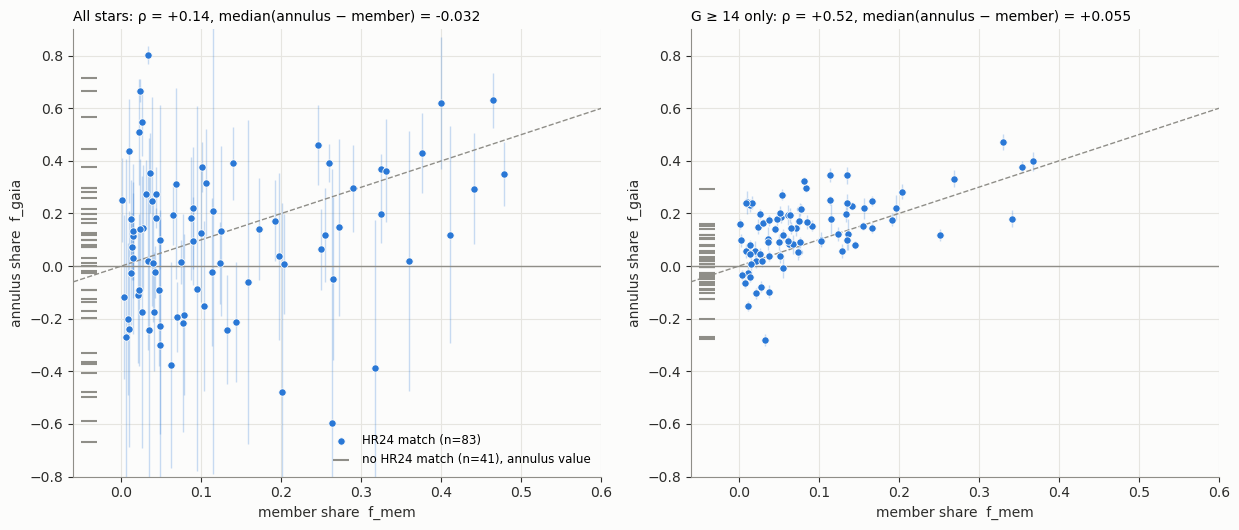

In [3]:
m = mm[mm.matched]
print(m[['f_mem', 'f_gaia', 'f_mem_Gmin14', 'f_Gmin14']].describe().round(3))
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.4))
for ax, (fm, fa, sg, ttl) in zip(axs, [('f_mem', 'f_gaia', 'sig_stoch', 'All stars'),
                                       ('f_mem_Gmin14', 'f_Gmin14', 'sig_Gmin14', 'G ≥ 14 only')]):
    ax.errorbar(m[fm], m[fa], yerr=m[sg].clip(upper=1), fmt='none', ecolor=MWC, alpha=.25, lw=1)
    ax.scatter(m[fm], m[fa], s=28, color=MWC, edgecolor='#fcfcfb', lw=.6, zorder=3,
               label=f'HR24 match (n={len(m)})')
    u = mm[~mm.matched]
    ax.scatter(np.full(len(u), -0.04), u[fa], marker='_', s=120, color=ALT, lw=1.5,
               label=f'no HR24 match (n={len(u)}), annulus value')
    lim = (-0.06, 0.6)
    ax.plot(lim, lim, color=MUTED, lw=1, ls='--'); ax.axhline(0, color=MUTED, lw=1)
    r = stats.spearmanr(m[fm], m[fa])
    med = (m[fa] - m[fm]).median()
    ax.set(xlim=lim, ylim=(-0.8, 0.9), xlabel='member share  f_mem', ylabel='annulus share  f_gaia')
    ax.set_title(f'{ttl}: ρ = {r.statistic:+.2f}, median(annulus − member) = {med:+.3f}',
                 loc='left', fontsize=10)
axs[0].legend(loc='lower right', fontsize=8.5)
fig.tight_layout(); save(fig, 'fig_mw_member_vs_annulus.png'); plt.show()

## 3 · Does HR24 miss cluster light? Stacked profile of the non-member light

For each matched cluster, the surface brightness in rings of 0.25 r_ap is computed for all
Gaia light and for the light left after removing HR24 members. Both are normalised to the
non-member level in the 1.5–2.5 r_ap annulus, and the median over clusters is plotted.
With a complete member list, the non-member curve would be flat at 1. A central rise is
cluster light that isn't in the member list.

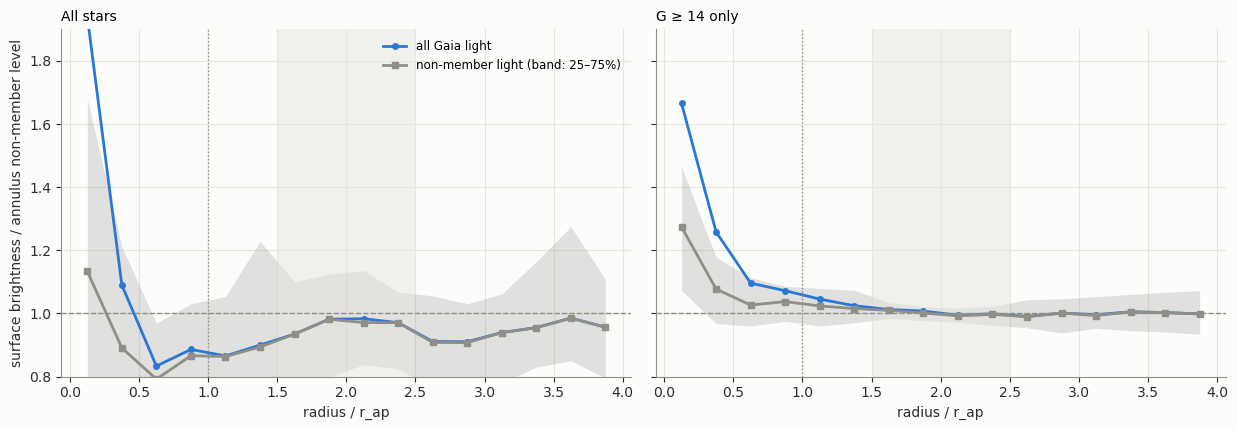

Non-member light inside r_ap above the annulus level, as a fraction of all aperture light (= cluster light HR24 misses, if the field is flat):


,median_missed_frac_of_aperture,q25,q75
stars,,,
all,-0.035,-0.234,0.138
G ≥ 14,0.063,-0.013,0.135


median G>=14 share of aperture light: 0.35; median correction 0.018; f_mem 0.079 -> f_mem_corr 0.130


In [4]:
profs = {g: ([], []) for g in [-99.0, 14.0]}
names, frac14 = [], []
for _, r in M.match_hr24(cl).dropna(subset=['hr_name']).iterrows():
    mem = M.members(r.hr_name)
    t = GS.ring_mag_table(r['name'], 'MW', r.ra, r.dec, r.r_ap_deg)
    ins = t[t.r_out <= 1 + 1e-9]
    names.append(r['name']); frac14.append(ins.f[ins.gbin >= 14].sum() / ins.f.sum())
    for g in profs:
        edges, p_all, p_non = M.nonmember_profile(r, mem, t, gmin=g)
        profs[g][0].append(p_all); profs[g][1].append(p_non)
mid = 0.5 * (edges[1:] + edges[:-1])
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
rows = []
for ax, (g, (pa, pn)) in zip(axs, profs.items()):
    pa, pn = np.array(pa), np.array(pn)
    ax.fill_between(mid, np.percentile(pn, 25, axis=0), np.percentile(pn, 75, axis=0), color=ALT, alpha=.25, lw=0)
    ax.plot(mid, np.median(pa, axis=0), color=MWC, marker='o', ms=4, label='all Gaia light')
    ax.plot(mid, np.median(pn, axis=0), color=ALT, marker='s', ms=4, label='non-member light (band: 25–75%)')
    ax.axhline(1, color=MUTED, lw=1, ls='--'); ax.axvline(1, color=MUTED, lw=1, ls=':')
    ax.axvspan(1.5, 2.5, color='#e6e5e0', alpha=.5, lw=0)
    ax.set(xlabel='radius / r_ap', ylim=(0.8, 1.9))
    ax.set_title('All stars' if g < 0 else 'G ≥ 14 only', loc='left', fontsize=10)
    inside = mid < 1
    area_w = (edges[1:] ** 2 - edges[:-1] ** 2)[inside]
    exc = np.array([np.sum((p[inside] - 1) * area_w) / np.sum(p[inside] * area_w) for p in pn])
    if g > 0:
        exc14 = pd.Series(exc, index=names)
    rows.append(dict(stars='all' if g < 0 else 'G ≥ 14',
                     median_missed_frac_of_aperture=np.median(exc),
                     q25=np.percentile(exc, 25), q75=np.percentile(exc, 75)))
axs[0].set_ylabel('surface brightness / annulus non-member level'); axs[0].legend(fontsize=8.5)
fig.tight_layout(); save(fig, 'fig_mw_nonmember_profile.png'); plt.show()
missed = pd.DataFrame(rows).set_index('stars')
print('Non-member light inside r_ap above the annulus level, as a fraction of all aperture light '
      '(= cluster light HR24 misses, if the field is flat):')
display(missed.round(3))

# The all-stars excess is dominated by bright-star sampling noise.  The G >= 14 excess is the
# clean measurement of missed (faint) members; convert it to all-light units per cluster.
corr = pd.DataFrame({'name': names, 'missed_G14': exc14.values, 'frac_light_G14': frac14})
corr['missed_all_units'] = corr.missed_G14.clip(lower=0) * corr.frac_light_G14
mm = mm.drop(columns=[c for c in corr.columns if c != 'name' and c in mm], errors='ignore').merge(corr, on='name', how='left')
mm['f_mem_corr'] = mm.f_mem + mm.missed_all_units
m = mm[mm.matched]
mm.to_csv(os.path.join(HERE, 'mw_member_share.csv'), index=False)
print(f'median G>=14 share of aperture light: {m.frac_light_G14.median():.2f}; '
      f'median correction {m.missed_all_units.median():.3f}; '
      f'f_mem {m.f_mem.median():.3f} -> f_mem_corr {m.f_mem_corr.median():.3f}')

## 4 · Ablations of the member share

- **Membership probability:** only members with Prob ≥ 0.5, 0.7 or 0.9.
- **Tidal radius:** only members flagged inside HR24's tidal radius (`inrt`).
- **Magnitude limit:** members and the denominator both restricted to G < 16…19.

In [5]:
ab = {'default (all HR24 members)': 'f_mem', 'Prob ≥ 0.5': 'f_mem_p0.5', 'Prob ≥ 0.7': 'f_mem_p0.7',
      'Prob ≥ 0.9': 'f_mem_p0.9', 'inside tidal radius': 'f_mem_inrt', 'G < 16': 'f_mem_G16',
      'G < 17': 'f_mem_G17', 'G < 18': 'f_mem_G18', 'G < 19': 'f_mem_G19', 'G ≥ 14': 'f_mem_Gmin14'}
abl = pd.DataFrame([dict(variant=k, median=m[c].median(), q16=m[c].quantile(.16), q84=m[c].quantile(.84),
                         median_shift=(m[c] - m.f_mem).median()) for k, c in ab.items()]).set_index('variant')
display(abl.round(3))
print(f'members in aperture per cluster: median {m.n_mem_in.median():.0f} '
      f'(16-84%: {m.n_mem_in.quantile(.16):.0f}-{m.n_mem_in.quantile(.84):.0f}); '
      f'brightest member carries a median {m.f_mem_brightest.median():.2f} of the member light; '
      f'faintest member G = {m.g_mem_faintest.median():.1f} (median)')

,median,q16,q84,median_shift
variant,,,,
default (all HR24 members),0.079,0.022,0.272,0.000
Prob ≥ 0.5,0.079,0.022,0.263,0.000
Prob ≥ 0.7,0.062,0.016,0.217,-0.007
Prob ≥ 0.9,0.030,0.009,0.139,-0.027
inside tidal radius,0.079,0.022,0.263,0.000
G < 16,0.100,0.015,0.320,0.006
G < 17,0.094,0.021,0.312,0.008
G < 18,0.088,0.022,0.293,0.007
G < 19,0.083,0.022,0.279,0.004


members in aperture per cluster: median 167 (16-84%: 46-533); brightest member carries a median 0.17 of the member light; faintest member G = 19.9 (median)


## 5 · Summary numbers

In [6]:
print('CONCLUSION —')
print(f'  HR24 recovers {m.shape[0]}/{len(mm)} MW clusters.')
u = mm[~mm.matched]
print(f'  Annulus share < 0 (G >= 14): {int((u.f_Gmin14 < 0).sum())}/{len(u)} unrecovered vs '
      f'{int((m.f_Gmin14 < 0).sum())}/{len(m)} recovered clusters.')
print(f'  Member share (recovered): median {m.f_mem.median():.3f}, 16-84% '
      f'{m.f_mem.quantile(.16):.3f}-{m.f_mem.quantile(.84):.3f}, none negative.')
print(f'  Annulus share for the same clusters: median {m.f_gaia.median():.3f} (all stars), '
      f'{m.f_Gmin14.median():.3f} (G >= 14).')
print(f'  Faint (G >= 14) member light HR24 misses: median {m.missed_G14.median():.3f} of the G >= 14 '
      f'aperture light -> completeness-corrected member share: median {m.f_mem_corr.median():.3f}, '
      f'16-84% {m.f_mem_corr.quantile(.16):.3f}-{m.f_mem_corr.quantile(.84):.3f}.')

CONCLUSION —
  HR24 recovers 83/124 MW clusters.
  Annulus share < 0 (G >= 14): 22/41 unrecovered vs 10/83 recovered clusters.
  Member share (recovered): median 0.079, 16-84% 0.022-0.272, none negative.
  Annulus share for the same clusters: median 0.113 (all stars), 0.144 (G >= 14).
  Faint (G >= 14) member light HR24 misses: median 0.063 of the G >= 14 aperture light -> completeness-corrected member share: median 0.130, 16-84% 0.045-0.312.


**What the member-based share says** (values from the cells above):

1. **Most of the persistent negatives are clusters Gaia doesn't recover.** HR24 finds no
   counterpart for 41/124 MW clusters (mostly FSR, Loden, ASCC and other MWSC entries). With
   the G ≥ 14 cut, 22 of those 41 have a negative annulus share (54%), against 10 of the 83
   recovered clusters (12%). Their median annulus share is ≈ 0. For about a third of the MW
   sample, Gaia sees no astrometric cluster in the aperture at all. Those apertures are field.
2. **For recovered clusters the member share is small and never negative:** median 0.08
   (16–84%: 0.02–0.27). Membership choices matter only at the strict end (Prob ≥ 0.9 halves it).
   The magnitude limit and tidal-radius flag barely change it.
3. **The annulus result is right on average but noisy per cluster.** With all stars the two
   methods barely agree cluster by cluster (ρ = +0.14), because bright field stars dominate
   the annulus error. With G ≥ 14 they agree well (ρ = +0.52), and the annulus value is higher
   by a median of +0.055.
4. **That offset is cluster light HR24 misses.** In the G ≥ 14 stacked profile the
   non-member light rises toward the centre (×1.27 in the inner quarter of the aperture), so
   about 6% of the faint aperture light belongs to the cluster but isn't in the member list.
   With that correction the member share is a median of **0.13** (16–84%: 0.05–0.31). This is
   bracketed by the annulus estimates (0.11 all stars, 0.14 for G ≥ 14).
5. **Bottom line for the MW:** the cluster contributes ~5–30% of the resolved light in
   recovered clusters (typically ~10%) and ≈ 0 in the third of apertures with no Gaia
   cluster. The light curves of MW clusters are field-dominated either way. The member
   method gives a per-cluster number without negative values; the annulus method only gets the
   population right.

**Caveats:** f_mem uses Gaia resolved light only, so unresolved light isn't in the
denominator, as in the annulus notebook. The missed-member correction assumes the field is flat
across the aperture. Saturated stars (G ≲ 3) are missing from both sums.